# workstream b, control 1: is it really the algorithm?

**question.** real gain falls over the rounds when newcomers compete with their own community (δ < 0). is that caused by the feedback loop (the model's own placements change the community it learned from), or would any change of the community of that size do the same?

**set-up.** the same simulation as the main experiment (v2 generator, gbm policy, capacity-constrained matching, 10 rounds × 2,000 arrivals, SOEP interactions). only who feeds the community changes:

| shift | who joins the community each round |
|---|---|
| `endogenous` | the people the model placed (the normal loop) |
| `quota` | the same number of people, placed at random by quota (independent of the model) |
| `shuffled` | the model's own per-origin flows, sent to randomly permuted states (same concentration, random direction) |

in every case the model still places the cohort, the outcomes are drawn in the world as it is, and the retrained model learns from its own placements. cohorts and noise are identical across shifts (same seed).

grid: `configs/exogenous.yaml` (δ ∈ {−0.3, 0, +0.3} × fixed / retrained every round × 3 shifts × 5 seeds). run it with
`python -m refugee_sim.simulation configs/exogenous.yaml`; this notebook only reads `results/exogenous/`.

`community_drift` = mean |z − z0| of the community shares after the round: how far the community has moved from the start, whatever moved it.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from refugee_sim.simulation import load_results

plt.rcParams.update({'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110})

runs = load_results('../results/exogenous')
print(f"{runs['run_key'].nunique()} runs loaded")

SHIFTS = ['endogenous', 'quota', 'shuffled']
SHIFT_LABEL = {'endogenous': 'endogenous (model feeds community)', 'quota': 'exogenous: quota arrivals',
               'shuffled': 'exogenous: shuffled flows'}
SHIFT_COLOR = {'endogenous': '#C0392B', 'quota': '#2F6FB5', 'shuffled': '#7FA7D9'}
POLICIES = ['fixed', 'every_round']
DELTAS = [-0.3, 0.0, 0.3]

90 runs loaded


## 1. control figure: real gain per round, endogenous vs exogenous shift

real gain over random quota placement (%). shaded = ± 1 sd across seeds. dotted = best possible gain (oracle) under the endogenous shift.

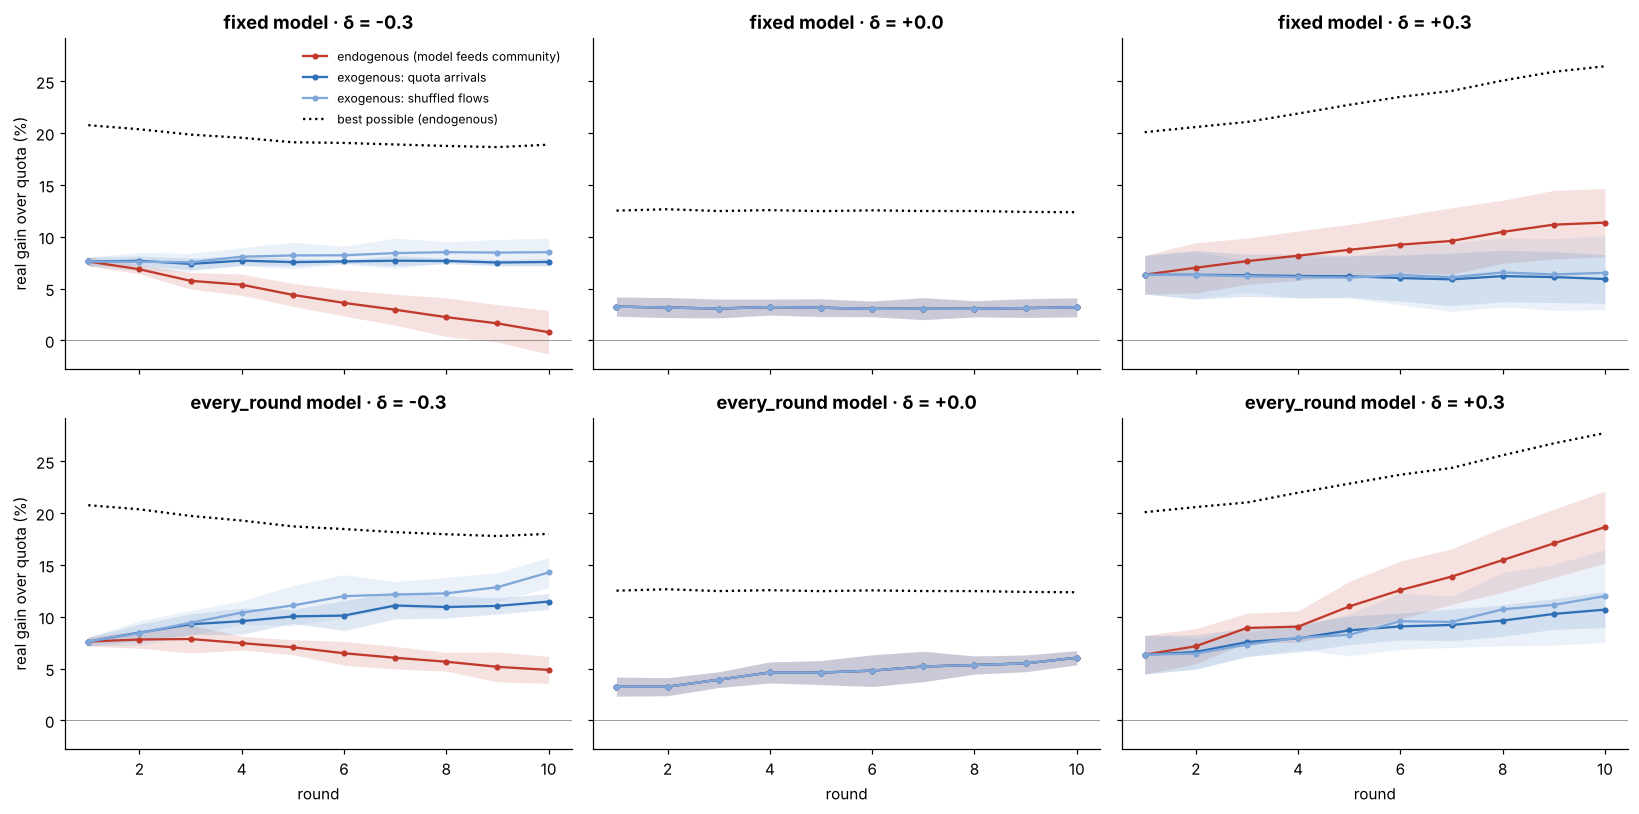

In [2]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7.5), sharex=True, sharey=True)
for i, p in enumerate(POLICIES):
    for j, d in enumerate(DELTAS):
        ax = axes[i, j]
        cell = runs[(runs['policy'] == p) & (runs['delta'] == d)]
        for s in SHIFTS:
            g = cell[cell['shift'] == s].groupby('round')['gain_pct'].agg(['mean', 'std'])
            ax.plot(g.index, g['mean'], '-o', ms=3, color=SHIFT_COLOR[s], label=SHIFT_LABEL[s])
            ax.fill_between(g.index, g['mean'] - g['std'], g['mean'] + g['std'], color=SHIFT_COLOR[s], alpha=0.15, lw=0)
        oracle = cell[cell['shift'] == 'endogenous'].groupby('round')['oracle_gain_pct'].mean()
        ax.plot(oracle.index, oracle, ':', color='k', label='best possible (endogenous)')
        ax.axhline(0, color='grey', lw=0.5)
        ax.set_title(f'{p} model · δ = {d:+.1f}', fontweight='bold')
        if j == 0:
            ax.set_ylabel('real gain over quota (%)')
        if i == 1:
            ax.set_xlabel('round')
axes[0, 0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig('../results/figures/ws_b_exogenous_control.png', dpi=150, bbox_inches='tight')
plt.show()

## 2. is the shift the same size?

how far the community moved from the start (mean |z − z0|), by round. the control is only fair if the exogenous lines reach a similar size as the endogenous one.

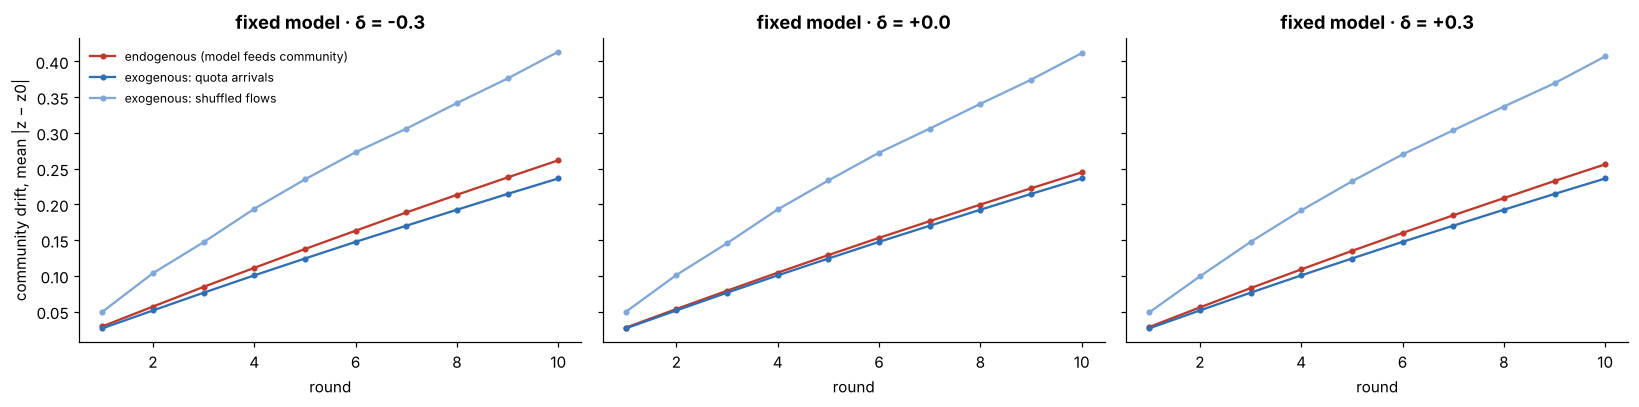

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), sharey=True)
fixed = runs[runs['policy'] == 'fixed']
for ax, d in zip(axes, DELTAS):
    for s in SHIFTS:
        m = fixed[(fixed['delta'] == d) & (fixed['shift'] == s)].groupby('round')['community_drift'].mean()
        ax.plot(m.index, m, '-o', ms=3, color=SHIFT_COLOR[s], label=SHIFT_LABEL[s])
    ax.set_title(f'fixed model · δ = {d:+.1f}', fontweight='bold')
    ax.set_xlabel('round')
axes[0].set_ylabel('community drift, mean |z − z0|')
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

## 3. table: degradation from round 1 to round 10

`drop` = real gain in round 1 minus round 10 (percentage points, mean over seeds; positive = got worse). `drop_vs_endogenous` = the exogenous drop as a share of the endogenous drop in the same cell (only shown where the endogenous drop is at least 1 point). small values mean the degradation comes from the feedback loop, not from the community change as such.

In [4]:
r = runs[runs['round'].isin([1, 10])]
wide = r.pivot_table(index=['delta', 'policy', 'shift', 'seed'], columns='round',
                     values=['gain_pct', 'captured_pct', 'community_drift'])
per_seed = pd.DataFrame({
    'gain_r1': wide[('gain_pct', 1)],
    'gain_r10': wide[('gain_pct', 10)],
    'drop': wide[('gain_pct', 1)] - wide[('gain_pct', 10)],
    'captured_r10': wide[('captured_pct', 10)],
    'drift_r10': wide[('community_drift', 10)],
})
table = per_seed.groupby(['delta', 'policy', 'shift']).mean()
table['drop_sd'] = per_seed.groupby(['delta', 'policy', 'shift'])['drop'].std()
endo = table.xs('endogenous', level='shift')['drop']
ref = endo.reindex(table.index.droplevel('shift')).to_numpy()
table['drop_vs_endogenous'] = np.where(ref >= 1, table['drop'] / ref, np.nan)
table = table[['gain_r1', 'gain_r10', 'drop', 'drop_sd', 'drop_vs_endogenous', 'captured_r10', 'drift_r10']]
table.to_csv('../results/figures/ws_b_exogenous_control.csv')
table.round(2)

gain_r1  gain_r10   drop  drop_sd  \
delta policy      shift                                           
-0.3  every_round endogenous     7.61      4.87   2.74     1.22   
                  quota          7.61     11.46  -3.85     1.07   
                  shuffled       7.61     14.27  -6.66     1.39   
      fixed       endogenous     7.61      0.78   6.83     1.82   
                  quota          7.61      7.56   0.05     0.23   
                  shuffled       7.61      8.51  -0.90     1.14   
 0.0  every_round endogenous     3.26      6.05  -2.79     0.78   
                  quota          3.26      6.05  -2.79     0.78   
                  shuffled       3.26      6.05  -2.79     0.78   
      fixed       endogenous     3.26      3.18   0.07     0.18   
                  quota          3.26      3.18   0.07     0.18   
                  shuffled       3.26      3.18   0.07     0.18   
 0.3  every_round endogenous     6.34     18.65 -12.31     2.05   
                  quota          6.34     10.69  -4.35     0.69   
                  shuffled       6.34     11.99  -5.66     3.50   
      fixed       endogenous     6.34     11.36  -5.02     1.75   
                  quota          6.34      5.92   0.42     0.64   
                  shuffled       6.34      6.52  -0.18     1.80   

                              drop_vs_endogenous  captured_r10  drift_r10  
delta policy      shift                                                    
-0.3  every_round endogenous                1.00         27.10       0.25  
                  quota                    -1.41         53.54       0.24  
                  shuffled                 -2.43         59.72       0.41  
      fixed       endogenous                1.00          4.33       0.26  
                  quota                     0.01         35.32       0.24  
                  shuffled                 -0.13         35.69       0.41  
 0.0  every_round endogenous                 NaN         48.89       0.24  
                  quota                      NaN         48.89       0.24  
                  shuffled                   NaN         48.89       0.41  
      fixed       endogenous                 NaN         25.85       0.24  
                  quota                      NaN         25.85       0.24  
                  shuffled                   NaN         25.85       0.41  
 0.3  every_round endogenous                 NaN         66.87       0.25  
                  quota                      NaN         55.20       0.24  
                  shuffled                   NaN         47.38       0.41  
      fixed       endogenous                 NaN         42.48       0.26  
                  quota                      NaN         30.63       0.24  
                  shuffled                   NaN         25.24       0.41

## 4. conclusion

**the degradation is caused by the feedback loop.** with competition (δ = −0.3) the fixed model loses 6.8 points of real gain from round 1 to round 10 when its own placements feed the community, and essentially nothing (0.0 points, quota) or slightly gains (shuffled) when the community is changed by an exogenous shift. the retrained model shows the same pattern: −2.7 points endogenous, while under both exogenous shifts it improves by 4–7 points.

**the shifts are comparable in size.** quota arrivals move the community as far as the model does (drift 0.24 vs 0.25 by round 10), and shuffled flows move it further (0.41). so the difference is not that the exogenous shift is smaller: it is that the model's shift is *aimed*, it pushes each origin into the states the model rated best, which is exactly where the competition hurts.

**sanity checks.** with no community effect (δ = 0) all three shifts give identical results, as they must. with δ = +0.3 the loop works the other way: the model's own concentration makes its favourite states better, so endogenous gain grows faster than under exogenous shifts (+5.0 vs ≈0 points for the fixed model).